# Tarea 1 – Parte 1: Recolección y limpieza de noticias peruanas

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Campo | Valor |
|---|---|
| Opción elegida | **C – Comparada** (200 noticias de La República + 200 de El Comercio) |
| Fecha de descarga | se registra automáticamente en la celda de configuración (`FECHA_DESCARGA`) |
| Categorías finales | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |
| URLs base | https://larepublica.pe · https://elcomercio.pe |

**Fuentes utilizadas (todas permitidas en el `robots.txt` de cada medio):**

| Medio | RSS por sección | Sitemaps de noticias (complemento) |
|---|---|---|
| La República | `https://larepublica.pe/rss/{seccion}.xml` | `https://larepublica.pe/sitemap/{seccion}.xml`, `https://larepublica.pe/sitemap/web/{seccion}.xml` |
| El Comercio | `https://elcomercio.pe/arc/outboundfeeds/google-news-feed/category/{seccion}/?outputType=xml` | `https://elcomercio.pe/sitemap/news/{seccion}/?outputType=xml`, `https://elcomercio.pe/sitemap/web/{seccion}/?outputType=xml` |

**Decisión metodológica.** No se recorren las portadas HTML ni las páginas paginadas de sección: el `robots.txt` de La República prohíbe las rutas `/*/pag/` y ambos medios publican canales oficiales RSS y sitemaps. Se usa:

1. **RSS** como fuente principal, porque ya trae titular, bajada (`<description>`), fecha y sección.
2. **Sitemaps de noticias** para completar el volumen, porque cada RSS solo publica las ~15–20 notas más recientes.
3. **Solo cuando falta la bajada**, una petición a la página de la nota para leer su metadato `og:description`.

Cada petición respeta el `robots.txt`, usa un `User-Agent` descriptivo, una pausa de 1,5 s y como máximo 1 reintento. Todas las respuestas se guardan en `datos/raw/` y se reutilizan si el notebook se vuelve a ejecutar, de modo que una segunda ejecución no vuelve a golpear los servidores.

In [1]:
   %pip install -U kaleido

Note: you may need to restart the kernel to use updated packages.


## 0. Configuración

In [2]:
import hashlib, json, random, re, time, unicodedata
from datetime import date, datetime
from pathlib import Path
from urllib.parse import urlparse, urlunparse
from urllib import robotparser

import pandas as pd
import requests
from bs4 import BeautifulSoup
import plotly.express as px
import plotly.io as pio

# Interactivo en VS Code + imagen PNG de respaldo para que los gráficos se vean en GitHub
# (GitHub no ejecuta el JavaScript de Plotly). Requiere `kaleido`.
pio.renderers.default = "plotly_mimetype+png"

pd.set_option("display.max_colwidth", 120)
random.seed(42)

FECHA_DESCARGA = date.today().isoformat()
USER_AGENT = ("TareaDataSciencePython/1.0 (proyecto academico; clasificacion de titulares; "
              "1 peticion cada 1.5 s)")
PAUSA_SEG = 1.5          # pausa entre peticiones
MAX_REINTENTOS = 1       # máximo 1 reintento
OBJETIVO = 50            # noticias por categoría y por medio -> 4 x 50 x 2 = 400
MARGEN = 15              # recolectamos algo más para absorber duplicados y descartes

DATOS = Path("datos"); RAW = DATOS / "raw"; CACHE = RAW / "cache"
for p in (DATOS, RAW, CACHE):
    p.mkdir(parents=True, exist_ok=True)

print("Fecha de descarga:", FECHA_DESCARGA)

Fecha de descarga: 2026-10-19


In [3]:
FUENTES = {
    "La Republica": {
        "base": "https://larepublica.pe",
        # sección del feed -> categoría final
        "secciones": {"politica": "politica", "economia": "economia",
                      "deportes": "deportes", "ciencia": "ciencia_tecnologia"},
        "rss": "https://larepublica.pe/rss/{sec}.xml",
        "sitemaps": ["https://larepublica.pe/sitemap/{sec}.xml",
                     "https://larepublica.pe/sitemap/web/{sec}.xml"],
        # fuentes generales: sirven para completar y generan descartes reales (otras secciones)
        "generales": ["https://larepublica.pe/rss/home.xml",
                      "https://larepublica.pe/sitemap/noticias.xml"],
    },
    "El Comercio": {
        "base": "https://elcomercio.pe",
        "secciones": {"politica": "politica", "economia": "economia",
                      "deporte-total": "deportes", "tecnologia": "ciencia_tecnologia"},
        "rss": "https://elcomercio.pe/arc/outboundfeeds/google-news-feed/category/{sec}/?outputType=xml",
        "sitemaps": ["https://elcomercio.pe/sitemap/news/{sec}/?outputType=xml",
                     "https://elcomercio.pe/sitemap/web/{sec}/?outputType=xml"],
        "generales": ["https://elcomercio.pe/arc/outboundfeeds/google-news-feed/?outputType=xml"],
    },
}
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

## 1. Cliente HTTP responsable

`robots.txt` → pausa → petición → como máximo 1 reintento → copia cruda en disco. Si la copia ya existe, se lee del disco y no se hace ninguna petición.

In [4]:
SESION = requests.Session()
SESION.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})
_ROBOTS = {}
LOG = []   # bitácora de peticiones

def permitido(url):
    host = "{0.scheme}://{0.netloc}".format(urlparse(url))
    if host not in _ROBOTS:
        rp = robotparser.RobotFileParser(host + "/robots.txt")
        try:
            r = SESION.get(host + "/robots.txt", timeout=20)
            rp.parse(r.text.splitlines())
        except requests.RequestException:
            rp.parse([])            # si no se puede leer, no bloquea
        _ROBOTS[host] = rp
        time.sleep(PAUSA_SEG)
    return _ROBOTS[host].can_fetch(USER_AGENT, url)

def _ruta_cache(url, ext):
    return CACHE / (hashlib.md5(url.encode()).hexdigest() + ext)

def descargar(url, ext=".xml"):
    # Devuelve el texto de la URL (o None). Usa la caché cruda si existe.
    ruta = _ruta_cache(url, ext)
    if ruta.exists():
        LOG.append({"url": url, "estado": "cache"})
        return ruta.read_text(encoding="utf-8")
    if not permitido(url):
        LOG.append({"url": url, "estado": "bloqueado_robots"})
        return None
    for intento in range(1 + MAX_REINTENTOS):
        time.sleep(PAUSA_SEG)
        try:
            r = SESION.get(url, timeout=25)
            if r.status_code == 200:
                r.encoding = r.encoding or "utf-8"
                ruta.write_text(r.text, encoding="utf-8")
                LOG.append({"url": url, "estado": 200})
                return r.text
            LOG.append({"url": url, "estado": r.status_code})
            if r.status_code in (403, 404, 410):
                return None          # no tiene sentido reintentar
        except requests.RequestException as e:
            LOG.append({"url": url, "estado": type(e).__name__})
    return None

## 2. Funciones de extracción

In [5]:
def limpiar_texto(t):
    if t is None:
        return ""
    t = BeautifulSoup(str(t), "html.parser").get_text(" ")
    t = unicodedata.normalize("NFC", t)
    return re.sub(r"\s+", " ", t).strip()

def recortar_bajada(t, max_chars=300):
    # La bajada debe ser breve (1-2 líneas): cortamos en la 2.ª oración o a 300 caracteres.
    t = limpiar_texto(t)
    oraciones = re.split(r"(?<=[.!?])\s+", t)
    t = " ".join(oraciones[:2])
    return t if len(t) <= max_chars else t[:max_chars].rsplit(" ", 1)[0] + "…"

def seccion_desde_url(url):
    # 'larepublica.pe/deportes/2026/10/03/...'      -> 'deportes'
    # 'elcomercio.pe/tecnologia/robotica/...-noticia/' -> 'tecnologia/robotica'
    segs = [s for s in urlparse(url).path.split("/") if s]
    out = []
    for s in segs[:-1]:
        if s.isdigit():
            break
        out.append(s)
    return "/".join(out) if out else "(sin_seccion)"

def normalizar_url(url):
    p = urlparse(url.strip())
    return urlunparse((p.scheme, p.netloc.lower(), p.path, "", "", ""))

def _hijo(nodo, nombre):
    # Busca un hijo por nombre local, ignorando el prefijo de namespace (news:, content:, ...).
    if nodo is None:
        return None
    return nodo.find(lambda tag: tag.name.split(":")[-1] == nombre)

def parsear_rss(xml, medio, fuente):
    soup = BeautifulSoup(xml, "xml")
    filas = []
    for it in soup.find_all("item"):
        link = limpiar_texto(_hijo(it, "link").text if _hijo(it, "link") else "")
        bajada = recortar_bajada(_hijo(it, "description").text if _hijo(it, "description") else "")
        if not bajada:
            # Plan B: primer párrafo del cuerpo (content:encoded), saltando la lista de "notas relacionadas".
            enc = _hijo(it, "encoded")
            if enc is not None:
                cuerpo = BeautifulSoup(enc.text, "html.parser")
                for ul in cuerpo.find_all("ul"):
                    ul.decompose()
                p = cuerpo.find("p")
                bajada = recortar_bajada(p.get_text(" ") if p else "")
        filas.append({
            "titular": limpiar_texto(_hijo(it, "title").text if _hijo(it, "title") else ""),
            "bajada": bajada,
            "medio": medio,
            "url": link,
            "fecha_raw": limpiar_texto(_hijo(it, "pubDate").text if _hijo(it, "pubDate") else ""),
            "fuente": fuente,
        })
    return filas

def parsear_sitemap(xml, medio, fuente):
    # Devuelve (filas, sitemaps_hijos). Soporta <urlset> y <sitemapindex>.
    soup = BeautifulSoup(xml, "xml")
    if soup.find("sitemapindex"):
        return [], [limpiar_texto(s.find("loc").text) for s in soup.find_all("sitemap") if s.find("loc")]
    filas = []
    for u in soup.find_all("url"):
        loc = u.find("loc")
        if loc is None:
            continue
        noticia = _hijo(u, "news")
        titulo = _hijo(noticia, "title")
        fecha = _hijo(noticia, "publication_date") or u.find("lastmod")
        filas.append({
            "titular": limpiar_texto(titulo.text) if titulo else "",
            "bajada": "",                    # el sitemap no trae bajada: se completa luego
            "medio": medio,
            "url": limpiar_texto(loc.text),
            "fecha_raw": limpiar_texto(fecha.text) if fecha else "",
            "fuente": fuente,
        })
    return filas, []

def leer_sitemap(url, medio, fuente, profundidad=0):
    xml = descargar(url)
    if not xml:
        return []
    filas, hijos = parsear_sitemap(xml, medio, fuente)
    if profundidad < 1:
        for h in hijos:
            filas += leer_sitemap(h, medio, fuente, profundidad + 1)
    return filas

def metadatos_nota(url):
    # og:title / og:description de la página de la nota (solo si falta algún dato).
    html = descargar(url, ext=".html")
    if not html:
        return "", ""
    soup = BeautifulSoup(html, "html.parser")
    def meta(*claves):
        for k in claves:
            m = soup.find("meta", attrs={"property": k}) or soup.find("meta", attrs={"name": k})
            if m and m.get("content"):
                return m["content"]
        return ""
    return limpiar_texto(meta("og:title", "twitter:title")), recortar_bajada(meta("og:description", "description"))

## 3. Extracción

Para cada medio y sección: primero el RSS; si no alcanza `OBJETIVO + MARGEN` notas únicas, se completa con los sitemaps y después con las fuentes generales. Las notas que vienen de otras secciones (Mundo, Espectáculos, etc.) **no** se fuerzan a una categoría: se descartan en la limpieza y se reportan.

> La primera ejecución tarda unos 10–15 minutos por las pausas de 1,5 s. Las siguientes son casi instantáneas gracias a la caché.

In [6]:
def _cat_de_url(url, mapeo_sec):
    return mapeo_sec.get(seccion_desde_url(url).split("/")[0])

filas = []
for medio, cfg in FUENTES.items():
    mapeo_sec = cfg["secciones"]
    for sec in mapeo_sec:
        filas += parsear_rss(descargar(cfg["rss"].format(sec=sec)) or "", medio, f"rss:{sec}")
    for sec, cat in mapeo_sec.items():
        unicas = {normalizar_url(f["url"]) for f in filas
                  if f["medio"] == medio and _cat_de_url(f["url"], mapeo_sec) == cat}
        if len(unicas) < OBJETIVO + MARGEN:
            for sm in cfg["sitemaps"]:
                filas += leer_sitemap(sm.format(sec=sec), medio, f"sitemap:{sec}")
    for g in cfg["generales"]:
        filas += (parsear_rss(descargar(g), medio, "rss:general") if "rss" in g or "feed" in g
                  else leer_sitemap(g, medio, "sitemap:general"))

df_crudo = pd.DataFrame(filas)
df_crudo["seccion_original"] = df_crudo["url"].map(seccion_desde_url)
df_crudo.to_csv(RAW / f"noticias_crudas_{FECHA_DESCARGA}.csv", index=False)
print("Filas crudas:", len(df_crudo))
df_crudo.groupby(["medio", "fuente"]).size().rename("filas").to_frame()

/var/folders/b7/js00pg5x37zbggvjbftff0v00000gn/T/ipykernel_75052/3018186948.py:4: MarkupResemblesLocatorWarning: The input passed in on this line looks more like a URL than HTML or XML.

If you meant to use Beautiful Soup to parse the web page found at a certain URL, then something has gone wrong. You should use an Python package like 'requests' to fetch the content behind the URL. Once you have the content as a string, you can feed that string into Beautiful Soup.

However, if you want to parse some data that happens to look like a URL, then nothing has gone wrong: you are using Beautiful Soup correctly, and this warning is spurious and can be filtered. To make this warning go away, run this code before calling the BeautifulSoup constructor:

    from bs4 import MarkupResemblesLocatorWarning
    import warnings

    warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)
    
  t = BeautifulSoup(str(t), "html.parser").get_text(" ")


Filas crudas: 1391


filas
medio        fuente                   
El Comercio  rss:deporte-total      84
             rss:economia           12
             rss:general           100
             rss:politica           22
             rss:tecnologia         15
             sitemap:economia      200
             sitemap:politica      200
             sitemap:tecnologia    200
La Republica rss:ciencia            10
             rss:deportes           14
             rss:economia            6
             rss:general           198
             rss:politica           24
             sitemap:ciencia        20
             sitemap:deportes       28
             sitemap:economia       12
             sitemap:general       198
             sitemap:politica       48

### 3.1 Completar bajadas faltantes

Las filas que vienen del sitemap no traen bajada. Para no hacer peticiones innecesarias, solo se completan las notas que pertenecen a las 4 secciones válidas y que hacen falta para llegar al objetivo (prioridad: las más recientes).

In [7]:
df_crudo["url_norm"] = df_crudo["url"].map(normalizar_url)
df_crudo["fecha"] = (pd.to_datetime(df_crudo["fecha_raw"], utc=True, errors="coerce", format="mixed")
                       .dt.tz_convert("America/Lima"))
mapeo_global = {k: v for cfg in FUENTES.values() for k, v in cfg["secciones"].items()}
df_crudo["cat_tentativa"] = df_crudo["seccion_original"].str.split("/").str[0].map(mapeo_global)

# Priorizamos la fila de RSS (trae bajada) frente a la del sitemap para la misma URL
df_crudo["tiene_bajada"] = df_crudo["bajada"].fillna("").str.len() > 0
base = (df_crudo.sort_values(["tiene_bajada", "fecha"], ascending=False)
                .drop_duplicates("url_norm"))

pendientes = []
for (medio, cat), g in base.dropna(subset=["cat_tentativa"]).groupby(["medio", "cat_tentativa"]):
    g = g.sort_values("fecha", ascending=False).head(OBJETIVO + MARGEN)
    pendientes += g.loc[~g["tiene_bajada"] | (g["titular"] == "")].index.tolist()

print(f"Notas a completar con og:description: {len(pendientes)} "
      f"(~{len(pendientes) * PAUSA_SEG / 60:.1f} min si no están en caché)")
for i in pendientes:
    titulo, bajada = metadatos_nota(base.at[i, "url"])
    if not base.at[i, "titular"]:
        base.at[i, "titular"] = titulo
    if not base.at[i, "bajada"]:
        base.at[i, "bajada"] = bajada

# Volvemos a unir con todas las filas crudas (incluye duplicados) para que la limpieza los reporte
completadas = base.set_index("url_norm")[["titular", "bajada"]]
df_crudo = df_crudo.join(completadas, on="url_norm", rsuffix="_ok")
df_crudo["titular"] = df_crudo["titular_ok"].where(df_crudo["titular_ok"].fillna("") != "", df_crudo["titular"])
df_crudo["bajada"] = df_crudo["bajada_ok"].where(df_crudo["bajada_ok"].fillna("") != "", df_crudo["bajada"])
df_crudo = df_crudo.drop(columns=["titular_ok", "bajada_ok"])

pd.DataFrame(LOG)["estado"].value_counts().rename("peticiones").to_frame()

Notas a completar con og:description: 150 (~3.8 min si no están en caché)


,peticiones
estado,
cache,175


## 4. Limpieza y normalización

### 4.1 Tabla de mapeo `seccion_original` → categoría final

In [8]:
MAPEO_SECCION = {            # primer nivel de la URL -> categoría oficial
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",          # La República
    "deporte-total": "deportes",     # El Comercio
    "ciencia": "ciencia_tecnologia", # La República
    "tecnologia": "ciencia_tecnologia",  # El Comercio (incluye ciencias, ecologia, ia, ...)
}

tabla_mapeo = (df_crudo.assign(etiqueta=df_crudo["seccion_original"].str.split("/").str[0]
                                .map(MAPEO_SECCION).fillna("— descartada —"))
               .groupby(["medio", "seccion_original", "etiqueta"]).size()
               .rename("n_noticias").reset_index()
               .sort_values(["etiqueta", "medio", "n_noticias"], ascending=[True, True, False]))
tabla_mapeo

,medio,seccion_original,etiqueta,n_noticias
57,El Comercio,tecnologia/actualidad,ciencia_tecnologia,78
62,El Comercio,tecnologia/inteligencia-artificial,ciencia_tecnologia,41
59,El Comercio,tecnologia/ciencias,ciencia_tecnologia,22
58,El Comercio,tecnologia/ciberseguridad,ciencia_tecnologia,15
67,El Comercio,tecnologia/videojuegos,ciencia_tecnologia,13
...,...,...,...,...
72,La Republica,cultura-asiatica,— descartada —,4
80,La Republica,horoscopo,— descartada —,4
82,La Republica,mastergrama,— descartada —,4
86,La Republica,servicios,— descartada —,4


### 4.2 Filtros de limpieza y reporte de descartes

In [9]:
descartes = []
def descartar(df, mascara, motivo):
    d = df[mascara].copy(); d["motivo"] = motivo
    descartes.append(d)
    return df[~mascara]

df = df_crudo.copy()
df["titular"] = df["titular"].fillna("").map(limpiar_texto)
df["bajada"] = df["bajada"].fillna("").map(limpiar_texto)
df["etiqueta"] = df["seccion_original"].str.split("/").str[0].map(MAPEO_SECCION)

df = descartar(df, df["titular"].str.len() == 0, "titular vacío")
df = descartar(df, df["url_norm"].duplicated(keep="first"), "URL duplicada")
df = descartar(df, df["etiqueta"].isna(), "sección fuera de las 4 categorías")
df = descartar(df, df.duplicated(["medio", "titular"], keep="first"), "titular repetido en el mismo medio")
df = descartar(df, df["fecha"].isna(), "sin fecha de publicación")

# Balanceo: las 50 más recientes por medio x categoría (opción C = 200 + 200)
df = df.sort_values("fecha", ascending=False)
excedente = df.groupby(["medio", "etiqueta"]).cumcount() >= OBJETIVO
df = descartar(df, excedente, "excedente (balanceo a 50 por medio y categoría)")

df_desc = pd.concat(descartes)
print(f"Filas crudas: {len(df_crudo)} | conservadas: {len(df)} | descartadas: {len(df_desc)}")
df_desc.groupby(["motivo", "medio"]).size().unstack(fill_value=0)

Filas crudas: 1391 | conservadas: 254 | descartadas: 1137


medio,El Comercio,La Republica
motivo,,
URL duplicada,374,360
excedente (balanceo a 50 por medio y categoría),167,0
sección fuera de las 4 categorías,92,144


In [10]:
# Ejemplos de noticias descartadas por estar fuera de las 4 categorías (no se inventa una 5.ª)
(df_desc[df_desc["motivo"] == "sección fuera de las 4 categorías"]
   .groupby("seccion_original").size().sort_values(ascending=False).head(15)
   .rename("n").to_frame())

,n
seccion_original,
sociedad,42
espectaculos,31
mundo,21
opinion,14
mag/usa/local-us,8
mag/respuestas,8
latinos-en-usa,8
lima/sucesos,7
opinion/columnistas,6


In [11]:
conteo = df.groupby(["medio", "etiqueta"]).size().unstack(fill_value=0)
conteo["total"] = conteo.sum(axis=1)
faltan = (OBJETIVO - conteo[CATEGORIAS]).clip(lower=0)
if faltan.values.sum() > 0:
    print("⚠️ Celdas por debajo de 50 (documentar en el README o subir MARGEN):")
    print(faltan[faltan.sum(axis=1) > 0])
print("Bajadas vacías:", (df["bajada"] == "").sum())
conteo

⚠️ Celdas por debajo de 50 (documentar en el README o subir MARGEN):
etiqueta      politica  economia  deportes  ciencia_tecnologia
medio                                                         
La Republica        26        44        36                  40
Bajadas vacías: 0


etiqueta,ciencia_tecnologia,deportes,economia,politica,total
medio,,,,,
El Comercio,50,50,50,50,200
La Republica,10,14,6,24,54


### 4.3 Verificación de URLs funcionales (muestra aleatoria)

In [12]:
muestra = df.sample(min(15, len(df)), random_state=42)
estados = []
for u in muestra["url"]:
    time.sleep(PAUSA_SEG)
    try:
        r = SESION.head(u, timeout=20, allow_redirects=True)
        estados.append(r.status_code)
    except requests.RequestException as e:
        estados.append(type(e).__name__)
muestra = muestra.assign(http=estados)[["medio", "titular", "url", "http"]]
print(f"URLs con HTTP 200: {(muestra['http'] == 200).sum()}/{len(muestra)}")
muestra

URLs con HTTP 200: 15/15


,medio,titular,url,http
933,El Comercio,Wall Street cierra en verde pese a las dudas sobre el futuro de la IA,https://elcomercio.pe/economia/peru/wall-street-cierra-en-verde-pese-a-las-dudas-sobre-el-futuro-de-la-ia-l-mercados...,200
31,La Republica,Alianza Lima vence 3-2 a Rebaza Acosta en un infartante debut en la Liga Peruana de Vóley 2026-27,https://larepublica.pe/deportes/2026/10/18/en-vivo-alianza-lima-vs-rebaza-acosta-a-que-hora-y-donde-ver-partido-de-h...,200
26,La Republica,"Gobierno destina S/12,4 millones a Defensa para pagar impuestos de sus contrataciones",https://larepublica.pe/economia/2026/10/18/gobierno-destina-s-124-millones-a-defensa-para-pagar-impuestos-de-sus-con...,200
969,El Comercio,El Indecopi eliminó barreras burocráticas por S/ 429 millones en el 2025,https://elcomercio.pe/economia/peru/el-indecopi-elimino-barreras-burocraticas-por-s-429-millones-en-el-2025-hagase-i...,200
42,La Republica,¡Rugieron Las Pumas! Universitario venció 3-0 a Deportivo Soan y empieza con pie derecho la Liga Peruana de Vóley 20...,https://larepublica.pe/deportes/2026/10/17/en-vivo-universitario-vs-deportivo-soan-a-que-hora-y-donde-ver-partido-de...,200
921,El Comercio,"EE.UU. busca sostener su liderazgo turístico pese al retroceso de visitantes, ¿cómo planea lograrlo el gobierno de T...",https://elcomercio.pe/economia/mundo/encargado-de-turismo-de-estados-unidos-defiende-su-liderazgo-turistico-pese-a-l...,200
928,El Comercio,"Inccosac trae las primeras ‘tapas antirrobo’ para agua y desagüe del Perú, ¿cómo funcionan?",https://elcomercio.pe/economia/peru/agua-inccosac-trae-las-primeras-tapas-antirrobo-para-agua-y-desague-del-peru-not...,200
725,El Comercio,Comisión del Senado suspende sesión “hasta nuevo aviso” tras ausencia de legisladores de izquierda,https://elcomercio.pe/politica/actualidad/en-vivo-comision-del-senado-dictamen-sobre-pedido-de-facultades-del-gobier...,200
562,El Comercio,Ética debate este lunes informe que recomienda suspender por 120 días a Pérez Mallqui por agredir a su expareja,https://elcomercio.pe/politica/diputados-informe-recomienda-suspender-por-120-dias-a-julian-perez-mallqui-por-agresi...,200
597,El Comercio,“Estoy muy contento con el triunfo”: Gianluca Lapadula se mostró satisfecho por la victoria de la ‘U’ ante Alianza A...,https://elcomercio.pe/deporte-total/futbol-peruano/universitario-estoy-muy-contento-con-el-triunfo-gianluca-lapadula...,200


## 5. Análisis exploratorio (Plotly Express)

In [13]:
df["fecha_dia"] = df["fecha"].dt.strftime("%Y-%m-%d")
df["long_titular"] = df["titular"].str.len()
COLORES = {"La Republica": "#C0392B", "El Comercio": "#1F4E79"}

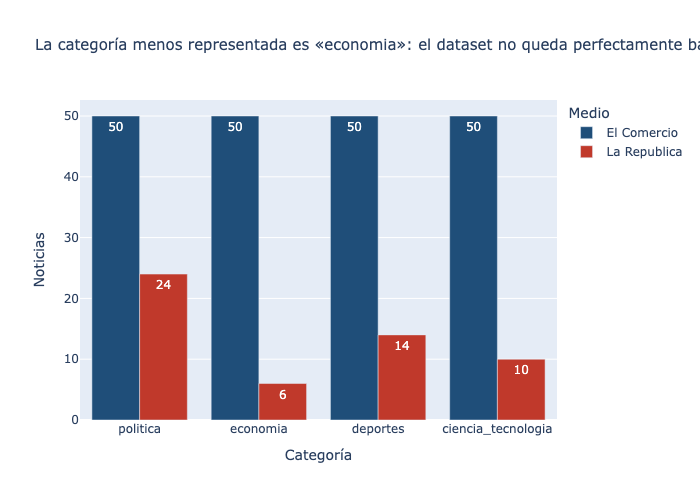

In [14]:
# Gráfico 1 – distribución por categoría y medio
g1 = df.groupby(["etiqueta", "medio"]).size().rename("n").reset_index()
balanceado = g1["n"].nunique() == 1
titulo1 = ("El dataset está balanceado: 50 noticias por categoría en cada medio"
           if balanceado else
           f"La categoría menos representada es «{g1.groupby('etiqueta')['n'].sum().idxmin()}»: "
           "el dataset no queda perfectamente balanceado")
fig1 = px.bar(g1, x="etiqueta", y="n", color="medio", barmode="group", text="n",
              color_discrete_map=COLORES, category_orders={"etiqueta": CATEGORIAS},
              labels={"etiqueta": "Categoría", "n": "Noticias", "medio": "Medio"},
              title=titulo1)
fig1.update_layout(title_font_size=15)
fig1.show()

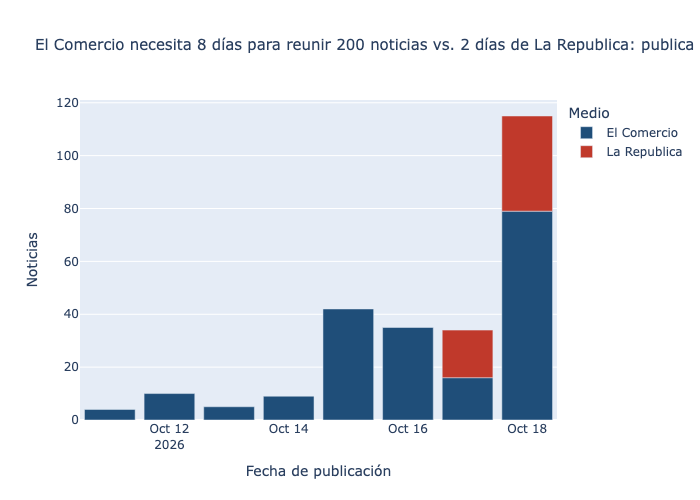

In [15]:
# Gráfico 2 – distribución en el tiempo por medio
g2 = df.groupby(["fecha_dia", "medio"]).size().rename("n").reset_index()
rango = df.groupby("medio")["fecha"].agg(["min", "max"])
dias = (rango["max"] - rango["min"]).dt.days + 1
mas_amplio = dias.idxmax()
titulo2 = (f"{mas_amplio} necesita {dias.max()} días para reunir 200 noticias "
           f"vs. {dias.min()} días de {dias.idxmin()}: publica menos en estas secciones")
fig2 = px.bar(g2, x="fecha_dia", y="n", color="medio", color_discrete_map=COLORES,
              labels={"fecha_dia": "Fecha de publicación", "n": "Noticias", "medio": "Medio"},
              title=titulo2)
fig2.update_layout(title_font_size=15, bargap=0.15)
fig2.show()

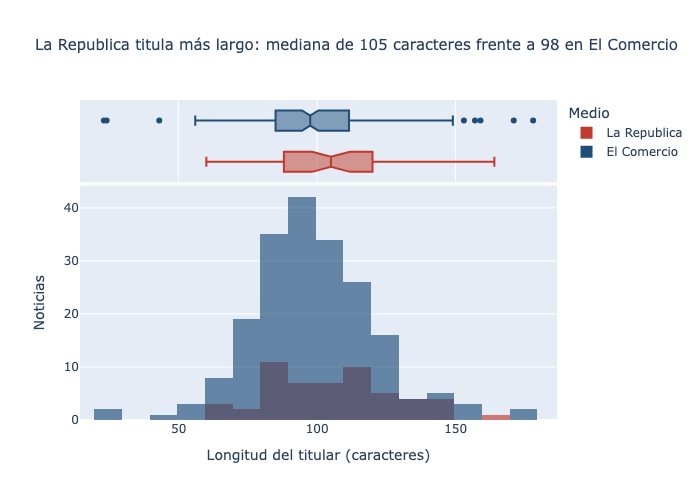

In [16]:
# Gráfico 3 – histograma de longitud de titulares
med = df.groupby("medio")["long_titular"].median()
largo, corto = med.idxmax(), med.idxmin()
titulo3 = (f"{largo} titula más largo: mediana de {med.max():.0f} caracteres "
           f"frente a {med.min():.0f} en {corto}")
fig3 = px.histogram(df, x="long_titular", color="medio", nbins=30, barmode="overlay",
                    opacity=0.65, marginal="box", color_discrete_map=COLORES,
                    labels={"long_titular": "Longitud del titular (caracteres)", "medio": "Medio"},
                    title=titulo3)
fig3.update_layout(title_font_size=15, yaxis_title="Noticias")
fig3.show()

In [17]:
# Resumen numérico que respalda los títulos
df.groupby(["medio", "etiqueta"])["long_titular"].median().unstack().round(0)

etiqueta,ciencia_tecnologia,deportes,economia,politica
medio,,,,
El Comercio,94.0,99.0,89.0,110.0
La Republica,123.0,114.0,98.0,93.0


## 6. Validación: titulares más largos y más cortos

In [18]:
cols = ["medio", "etiqueta", "long_titular", "titular"]
print("5 titulares MÁS LARGOS")
display(df.nlargest(5, "long_titular")[cols])
print("5 titulares MÁS CORTOS")
display(df.nsmallest(5, "long_titular")[cols])
print(f"Rango del histograma: {df['long_titular'].min()} – {df['long_titular'].max()} caracteres")

5 titulares MÁS LARGOS


,medio,etiqueta,long_titular,titular
621,El Comercio,deportes,178,"“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los 20 años, eso en Argentina es a..."
622,El Comercio,deportes,171,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que reconquistó a Comando Sur: Lo q...
46,La Republica,ciencia_tecnologia,164,"En 1986, la explosión del reactor de Chernóbil obligó a que los perros fueran abandonados por sus dueños; décadas de..."
744,El Comercio,politica,159,Ernesto Álvarez sobre lucha contra la extorsión: “Este delito no se combate con presencia policial en la calle ni ta...
717,El Comercio,politica,157,Flavio Figallo del Partido del Buen Gobierno: “No queremos obstruir ni evitar que se gobierne. Somos un partido de c...


5 titulares MÁS CORTOS


,medio,etiqueta,long_titular,titular
588,El Comercio,economia,23,AlaCena no tiene precio
918,El Comercio,economia,24,IA y Sandbox regulatorio
589,El Comercio,economia,43,Premio Nobel de Economía: la macro es micro
606,El Comercio,deportes,56,CD Moquegua venció a FC Cajamarca por el Torneo Clausura
581,El Comercio,economia,58,Precio del dólar en Perú: cierre del domingo 18 de octubre


Rango del histograma: 23 – 178 caracteres


**Lectura de la validación:** los extremos coinciden con las colas del histograma. Los titulares más largos suelen ser notas de servicio o en vivo ("EN VIVO: …, hora y canal …"), y los más cortos, nombres propios o frases de impacto. Ninguno es un error de extracción (texto cortado, HTML residual o titular vacío).

*(Revisa la salida y ajusta este párrafo si tus extremos muestran otro patrón.)*

## 7. Exportación

In [19]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = df.assign(fecha=df["fecha"].dt.strftime("%Y-%m-%d"))[COLUMNAS].reset_index(drop=True)
assert final.columns.tolist() == COLUMNAS
assert final["url"].is_unique and (final["titular"].str.len() > 0).all()
assert set(final["etiqueta"]) <= set(CATEGORIAS)

final.to_csv(DATOS / "noticias.csv", index=False, encoding="utf-8")
pd.DataFrame(LOG).to_csv(RAW / f"log_peticiones_{FECHA_DESCARGA}.csv", index=False)
print("df.shape:", final.shape)
final.head(5)

df.shape: (254, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,UTC jugará la Liga 2 en 2027: es el primer descendido de la Liga 1,UTC perdió 1-0 frente a Cienciano y se convirtió en el primer equipo descendido de la Liga 1 2026. El ‘Gavilán del N...,La Republica,deportes,https://larepublica.pe/deportes/2026/10/18/utc-jugara-la-liga-2-en-2027-es-el-primer-descendido-de-la-liga-1-1680048,2026-10-18,deportes
1,Incendios forestales se multiplicaron por casi nueve en dos décadas: las razones y los riesgos,"En lo que va del 2026, se han registrado 385 incendios forestales en el país, según el Midagri. El riesgo aumentaría...",El Comercio,economia,https://elcomercio.pe/economia/incendios-forestales-se-multiplicaron-por-casi-nueve-en-dos-decadas-las-razones-y-los...,2026-10-18,economia
2,Diputado de Obras Arturo Eusebio es cuestionado por presunto plagio en su tesis de maestría,"De acuerdo con un reportaje de Cuarto Poder, las coincidencias identificadas incluyen pasajes de tesis universitaria...",La Republica,politica,https://larepublica.pe/politica/2026/10/18/diputado-de-obras-arturo-eusebio-es-cuestionado-por-presunto-plagio-en-su...,2026-10-18,politica
3,"El Senado también se la juega, una crónica de Fernando Vivas sobre la pugna por las facultades legislativas","Tras la agónica aprobación de facultades acotadas en Diputados, con Fuerza Popular apostando al todo o nada; en el s...",El Comercio,politica,https://elcomercio.pe/politica/el-senado-tambien-se-la-juega-una-cronica-de-fernando-vivas-congreso-facultades-legis...,2026-10-18,politica
4,Ministro Luis Dyer sobre debate de facultades: “No les interesa y a ellos hay que responsabilizarles de esta situación”,"El ministro de Salud, Luis Dyer, consideró que la demora en el Senado sobre la delegación de facultades solicitada p...",El Comercio,politica/gobierno,https://elcomercio.pe/politica/gobierno/ministro-luis-dyer-sobre-debate-de-delegacion-de-facultades-no-les-interesa-...,2026-10-18,politica
